### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema, savgol_filter

In [2]:
# load data
signals = np.load('checkpoint1dataset.npy')

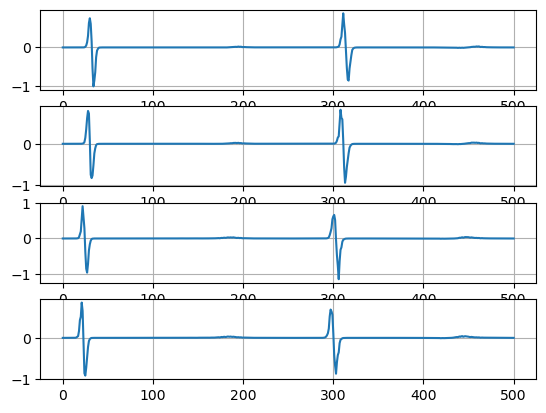

In [3]:
# select event to be display
ind_event = 0

# select a spline (options: 0,1,2,3,4)
ind_spline = 3

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

In [4]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.signal import savgol_filter, argrelextrema

# # --- CONFIGURAZIONE ---
# ev_test = 3
# spline_sensors = [8, 9, 10, 5] 
# window_length = 15
# poly_order = 3
# min_dist = 100 

# # Pre-processing (Savgol è essenziale per l'Onset)
# signals_filtered = np.zeros_like(signals)
# for ev in range(signals.shape[0]):
#     for sens in range(signals.shape[1]):
#         signals_filtered[ev, sens, :] = savgol_filter(signals[ev, sens, :], window_length, poly_order)

# # --- PLOTTING CON ANALISI ONSET ---
# n_sens = len(spline_sensors)
# fig, axs = plt.subplots(2, n_sens, figsize=(4 * n_sens, 9), sharex=True)

# if n_sens == 1: axs = axs.reshape(2, 1)

# for i, sens_idx in enumerate(spline_sensors):
#     sig_filt = signals_filtered[ev_test, sens_idx, :]
#     ds_filt = np.diff(sig_filt)
    
#     # 1. Trova i picchi di attivazione (minimi derivata)
#     min_indices = argrelextrema(ds_filt, np.less)[0]
#     selected_peaks = []
#     if len(min_indices) > 0:
#         depths = ds_filt[min_indices]
#         candidates = min_indices[np.argsort(depths)]
#         for c in candidates:
#             if len(selected_peaks) == 0 or all(abs(c - p) > min_dist for p in selected_peaks):
#                 selected_peaks.append(c)
#             if len(selected_peaks) == 2: break
#     selected_peaks.sort()

#     # 2. Calcolo dell'Onset (Distacco dalla baseline)
#     onsets = []
#     for p in selected_peaks:
#         # Analizziamo una finestra di 50 campioni prima del picco
#         search_back = 50
#         start_win = max(0, p - search_back)
#         window = sig_filt[start_win : p]
        
#         # Calcoliamo la baseline e una soglia di distacco dinamica (noise floor)
#         # Usiamo i primi 10 campioni della finestra come riferimento di "quiete"
#         local_baseline = np.mean(sig_filt[start_win : start_win + 10])
#         noise_std = np.std(sig_filt[start_win : start_win + 10])
#         threshold = max(3 * noise_std, 0.02 * (np.max(sig_filt) - np.min(sig_filt)))
        
#         # Torniamo indietro dal picco p finché il segnale non rientra nella soglia
#         onset_idx = p
#         for k in range(p, start_win, -1):
#             if abs(sig_filt[k] - local_baseline) < threshold:
#                 onset_idx = k
#                 break
#         onsets.append(onset_idx)

#     # --- RIGA 1: SEGNALE + ONSET ---
#     axs[0, i].plot(sig_filt, color='blue', linewidth=1.5, label='Filt')
#     for idx_o in onsets:
#         # Cerchio verde sul punto di distacco
#         axs[0, i].plot(idx_o, sig_filt[idx_o], 'go', markersize=10, markeredgecolor='black', label='Onset' if idx_o == onsets[0] else "")
#         # Linea verticale per confronto temporale
#         axs[0, i].axvline(x=idx_o, color='green', linestyle='--', alpha=0.6)
#         # Annotazione del tempo di onset
#         axs[0, i].text(idx_o, sig_filt[idx_o] + 0.1, f'T:{idx_o}', color='green', fontweight='bold', ha='center')

#     axs[0, i].set_title(f'Sensore {sens_idx}', fontsize=12, fontweight='bold')
#     axs[0, i].grid(True, alpha=0.2)
#     if i == 0: axs[0, i].legend()

#     # --- RIGA 2: DERIVATA ---
#     axs[1, i].plot(ds_filt, color='red', linewidth=1)
#     for p in selected_peaks:
#         axs[1, i].plot(p, ds_filt[p], 'ro')
#         axs[1, i].text(p, ds_filt[p] - 0.05, f'Act:{p}', color='red', fontsize=8, ha='center')
    
#     axs[1, i].set_title('Derivata (Pendenza)', fontsize=10)
#     axs[1, i].grid(True, alpha=0.2)

# plt.suptitle(f'Analisi Onset vs Activation - Evento {ev_test}\nIl cerchio verde indica il primo distacco dalla baseline (indipendentemente dalla R o S)', 
#              fontsize=14, fontweight='bold', y=0.98)
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()

In [ ]:
def GroupSolutionCP1(signals_event):
    # --- 0. FILTRAGGIO PREVENTIVO (Savitzky-Golay) ---
    # Applichiamo il filtro per pulire le oscillazioni senza spostare i tempi
    # window_length=15, polyorder=3 è il setup ideale per non perdere i picchi
    signals_cleaned = savgol_filter(signals_event, window_length=15, polyorder=3, axis=1)
    
    n_sensors = signals_cleaned.shape[0]
    timings = []
    min_dist = 100 
    time_tol = 4
    
    act_times = [[], []] 
    qs_flags = [[], []]
    slopes_list = [[], []]
    onsets_list = [[], []]

    # Derivata sui segnali filtrati
    ds_all = np.diff(signals_cleaned, axis=1)
    global_min_slope = np.min(ds_all)
    slope_threshold = 0.30 * global_min_slope

    for i in range(n_sensors):
        # Usiamo i segnali puliti per tutto il resto della riga
        sig_i = signals_cleaned[i, :]
        ds = np.diff(sig_i)
        
        all_min_indices = argrelextrema(ds, np.less)[0]
        valid_min_indices = [idx for idx in all_min_indices if ds[idx] <= slope_threshold]
        min_indices = np.array(valid_min_indices)
        
        selected = []
        qs_status = [False, False]
        sensor_slopes = [np.nan, np.nan]
        sensor_onsets = [np.nan, np.nan]
        
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()
            
            for j, val in enumerate(selected):
                window_start = max(0, val - 30)
                window_end = min(signals_cleaned.shape[1], val + 30)
                
                baseline = np.mean(sig_i[window_start : window_start + 5])
                max_pos = np.max(sig_i[window_start : val]) - baseline
                max_neg = np.min(sig_i[val : window_end]) - baseline
                
                if max_pos < 0.2 * abs(max_neg):
                    qs_status[j] = True
                
                sensor_slopes[j] = ds[val]
                
                # Calcolo Onset su segnale pulito
                search_back = 40
                start_win = max(0, val - search_back)
                local_baseline = np.mean(sig_i[start_win : start_win + 5])
                noise_std = np.std(sig_i[start_win : start_win + 5])
                thresh = max(3 * noise_std, 0.05 * abs(max_neg)) 
                
                onset_idx = val
                for k in range(val, start_win, -1):
                    if abs(sig_i[k] - local_baseline) < thresh:
                        onset_idx = k
                        break
                sensor_onsets[j] = onset_idx

        row_time = [None, None]
        for j in range(len(selected)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

        for j in range(2):
            t_val = row_final[j] if not np.isnan(row_final[j]) else np.inf
            act_times[j].append(t_val)
            qs_flags[j].append(qs_status[j])
            slopes_list[j].append(sensor_slopes[j])
            onsets_list[j].append(sensor_onsets[j])

    # --- LOGICA LS ---
    LS_array = np.zeros((n_sensors, 2))
    for j in range(2):
        times = np.array(act_times[j]); flags = np.array(qs_flags[j])
        slopes = np.array(slopes_list[j]); onsets = np.array(onsets_list[j])
        valid_idxs = np.where(~np.isinf(times) & ~np.isnan(times))[0]
        if len(valid_idxs) == 0: continue
        
        winners = []
        qs_candidates = [idx for idx in valid_idxs if flags[idx]]
        
        if qs_candidates:
            qs_candidates.sort(key=lambda x: times[x])
            best = qs_candidates[0]
            winners.append(best)
            if len(qs_candidates) > 1:
                second = qs_candidates[1]
                if abs(times[second] - times[best]) <= time_tol:
                    winners.append(second)
        else:
            timing_candidates = list(valid_idxs)
            timing_candidates.sort(key=lambda x: times[x])
            best = timing_candidates[0]
            winners.append(best)
            if len(timing_candidates) > 1:
                second = timing_candidates[1]
                if abs(times[second] - times[best]) <= time_tol:
                    winners.append(second)

        # Bilancio e Sanity Check finale
        if winners:
            avg_winner_onset = np.mean([onsets[w] for w in winners])
            avg_winner_slope = np.mean([slopes[w] for w in winners])
            challengers = []
            for idx in valid_idxs:
                if idx not in winners:
                    onset_is_way_earlier = onsets[idx] < (avg_winner_onset - 5)
                    slope_is_way_steeper = slopes[idx] < (avg_winner_slope * 1.5)
                    if onset_is_way_earlier or slope_is_way_steeper:
                        challengers.append(idx)
            if challengers:
                pool = winners + challengers
                pool.sort(key=lambda x: (onsets[x], slopes[x]))
                new_best = pool[0]
                winners = [new_best]
                for other in pool[1:]:
                    if abs(onsets[other] - onsets[new_best]) <= time_tol:
                        winners.append(other)
                        if len(winners) == 2: break

        if len(winners) == 1: LS_array[winners[0], j] = 1.0
        elif len(winners) >= 2:
            LS_array[winners[0], j] = 0.5; LS_array[winners[1], j] = 0.5
        
    return timings, LS_array.tolist()

In [6]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print(timings_event)
print("LS_event", LS_event)

[[16, 271], [14, 273], [13, 282], [14, 285], [31, 294], [30, 293], [24, 291], [22, 291], [37, 312], [35, 309], [28, 301], [25, 299], [31, 313], [29, 310], [23, 302], [22, 300], [15, 299], [13, 297], [13, 294], [14, 293]]
LS_event [[0.0, 0.5], [0.0, 0.5], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0]]


In [7]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Assicurati che sensor_locs e gt_focal siano caricati correttamente
# # n_events = 5 

# fig, axes = plt.subplots(2, n_events, figsize=(5 * n_events, 10), sharex=True, sharey=True)

# if n_events == 1:
#     axes = np.array(axes).reshape(2, 1)

# for ev in range(n_events):
#     sig_ev = signals[ev, :, :]
#     timings, LS = GroupSolutionCP1(sig_ev)
    
#     timings_arr = np.array(timings, dtype=float)
#     ls_arr = np.array(LS, dtype=float)

#     for beat_idx in range(2):
#         ax = axes[beat_idx, ev]
        
#         # 1. Recupero GT per questo battito
#         gp = [np.nan, np.nan]
#         if ev < gt_focal.shape[0] and beat_idx < gt_focal.shape[1]:
#             gp = gt_focal[ev, beat_idx]

#         # 2. Calcolo distanze per TUTTI i sensori
#         dist_all = []
#         if not np.isnan(gp[0]):
#             for i in range(len(sensor_locs)):
#                 d = np.sqrt(np.sum((sensor_locs[i] - gp)**2))
#                 dist_all.append(d)
#         dist_all = np.array(dist_all)

#         # 3. Plot Mappa di Attivazione
#         first_act = timings_arr[:, beat_idx]
#         valid = np.isfinite(first_act)
        
#         if np.any(valid):
#             sc = ax.scatter(
#                 sensor_locs[valid, 0], sensor_locs[valid, 1],
#                 c=first_act[valid], cmap='viridis', s=130, 
#                 edgecolors='k', linewidths=0.3, zorder=2
#             )
#             plt.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)

#         # 4. Overlay GT (X arancione) e Predizione (Stella Rossa)
#         ax.scatter(gp[0], gp[1], marker='X', s=180, c='orange', edgecolors='black', zorder=5, label='GT')
        
#         pred_idx = np.where(ls_arr[:, beat_idx] > 0)[0]
#         if len(pred_idx) > 0:
#             ax.scatter(sensor_locs[pred_idx, 0], sensor_locs[pred_idx, 1],
#                        marker='*', s=380, c='crimson', edgecolors='black', zorder=6, label='Pred')

#         # 5. STAMPA DELLE DISTANZE (Top 5 sensori più vicini al GT)
#         if len(dist_all) > 0:
#             nearest_idxs = np.argsort(dist_all)[:5] # Prendiamo i 5 più vicini
#             text_str = "Nearest to GT:\n"
#             for n_idx in nearest_idxs:
#                 is_pred = "*" if n_idx in pred_idx else ""
#                 text_str += f"S{n_idx}: {dist_all[n_idx]:.2f} {is_pred}\n"
            
#             # Posizioniamo il testo in un box dentro il grafico
#             ax.text(0.05, 0.95, text_str, transform=ax.transAxes, fontsize=8,
#                     verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

#         # Etichette sensori per orientarsi
#         for i, (x, y) in enumerate(sensor_locs):
#             ax.annotate(str(i), (x, y), fontsize=7, alpha=0.5, ha='center')

#         ax.set_title(f'Ev {ev} - Battito {beat_idx+1}')
#         ax.set_aspect('equal')
#         ax.grid(True, alpha=0.15)

# plt.suptitle('Validazione Distanze: I sensori con * sono quelli scelti dal tuo codice', fontsize=14, fontweight='bold')
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()